# 01. 기본 EDA + 피처 엔지니어링 — 서울 아파트 최근 5년

`02_eda_feature_engineering_final.ipynb`를 base / subway / school 세 단계로 분리한 첫 번째 노트북입니다.

이 노트북에서 수행하는 작업:
- 원본 실거래 데이터 로드 및 품질 점검
- 모델링 대상 거래 정리
- 기본 + 시간 피처, 서울 수집 범위 검증, 5년 시간축 EDA
- 누수 없는 과거 월 기반 시장(lag) 피처
- 카카오 API를 이용한 아파트 좌표 지오코딩

지하철·학교 인프라 피처는 이 노트북의 결과(`df_fe_base.parquet`)를 불러와
[02_subway_feature_engineering.ipynb](02_subway_feature_engineering.ipynb),
[03_school_feature_engineering.ipynb](03_school_feature_engineering.ipynb)에서 각각 이어서 만듭니다.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

load_dotenv()


# ------------------------------------------------------------------
# 경로 설정
# ------------------------------------------------------------------

# 현재 위치:
# Apartment price/notebook/v2_5year_notebook/eda
PROJECT_DIR = Path.cwd().parents[2]

DATA_ROOT = PROJECT_DIR / "data"

# V2 서울 5년 데이터
DATA_DIR = DATA_ROOT / "v2_5year_seoul"

PROCESSED_DIR = DATA_DIR / "processed"

# V1 / V2 공통 외부 데이터
EXTERNAL_DIR = DATA_ROOT / "external"


# ------------------------------------------------------------------
# 파일 경로
# ------------------------------------------------------------------

RAW_PATH = (
    PROCESSED_DIR / "apt_trade_raw.parquet"
)

SIGUNGU_PATH = (
    PROCESSED_DIR / "sigungu_map.csv"
)

DF_FE_PATH = (
    PROCESSED_DIR / "df_fe.parquet"
)

MARKET_MONTHLY_PATH = (
    PROCESSED_DIR / "market_monthly.parquet"
)


# ------------------------------------------------------------------
# 입력 파일 확인
# ------------------------------------------------------------------

if not RAW_PATH.exists():
    raise FileNotFoundError(
        f"원본 데이터가 없습니다.\n"
        f"경로: {RAW_PATH}\n"
        f"먼저 01_data_collection.ipynb를 실행하세요."
    )

if not SIGUNGU_PATH.exists():
    raise FileNotFoundError(
        f"서울 시군구 코드 파일이 없습니다.\n"
        f"경로: {SIGUNGU_PATH}"
    )


# ------------------------------------------------------------------
# 데이터 로드
# ------------------------------------------------------------------

raw_df = pd.read_parquet(
    RAW_PATH
)

sigungu_df = pd.read_csv(
    SIGUNGU_PATH,
    encoding="utf-8-sig",
    dtype={
        "시군구코드": str
    }
)


# ------------------------------------------------------------------
# 확인
# ------------------------------------------------------------------

print("[입력 데이터]")
print("RAW_PATH     :", RAW_PATH.resolve())
print("SIGUNGU_PATH :", SIGUNGU_PATH.resolve())
print("원본 shape   :", raw_df.shape)
print("시군구 수    :", len(sigungu_df))

display(raw_df.head())

[입력 데이터]
RAW_PATH     : C:\Users\UK\Apartment price\data\v2_5year_seoul\processed\apt_trade_raw.parquet
SIGUNGU_PATH : C:\Users\UK\Apartment price\data\v2_5year_seoul\processed\sigungu_map.csv
원본 shape   : (247385, 33)
시군구 수    : 25


,법정동시군구코드,법정동읍면동코드,법정동지번코드,법정동본번코드,법정동부번코드,도로명,도로명시군구코드,도로명코드,도로명일련번호코드,도로명지상지하코드,...,해제여부,해제사유발생일,거래유형,중개사소재지,등기일자,아파트동명,매도자,매수자,토지임대부아파트여부,거래연월
0,11110,18700,1,82,0,통일로,11110.0,3000008.0,6.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,N,202107
1,11110,11500,1,9,0,사직로8길,11110.0,4100135.0,3.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,N,202107
2,11110,17900,1,199,0,송월길,11110.0,4100192.0,1.0,NaN,...,nan,nan,nan,nan,nan,nan,nan,nan,N,202107
3,11110,18700,1,82,0,통일로,11110.0,3000008.0,6.0,0.0,...,O,22.01.03,nan,nan,nan,nan,nan,nan,N,202107
4,11110,11800,1,73,0,새문안로3길,11110.0,4100158.0,2.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,N,202107


5년 버전에서는 원본 행 수를 문서에 고정값으로 적지 않습니다.

수집 종료월, 신고 지연, API 재수집 시점에 따라 거래건수가 달라질 수 있으므로
위 셀에서 **실제 shape와 수집 기간을 매번 확인**합니다.

이후 분석은 서울 아파트 데이터만 존재하는 것을 전제로 하되,
3번 섹션에서 서울 외 코드가 섞이지 않았는지 다시 검증합니다.


## 1. 기본 데이터 품질 점검

핵심 컬럼:
- 계약년도 / 계약월 / 계약일
- 법정동시군구코드
- 거래금액
- 전용면적
- 건축년도
- 층
- 법정동 / 지번 / 단지명

5년 데이터에서는 결측치뿐 아니라 **기간 누락, 연도별 거래량 급변, 최근 월 신고 미완결**도 함께 확인합니다.


In [2]:
print("[원본 dtype]")
print(raw_df.dtypes)


# ----------------------------------------------------------
# 문자열로 변환된 결측값 복원
# ----------------------------------------------------------

object_cols = raw_df.select_dtypes(
    include=["object", "string"]
).columns

for col in object_cols:
    raw_df[col] = (
        raw_df[col]
        .replace({
            "nan": pd.NA,
            "None": pd.NA,
            "NaN": pd.NA,
            "null": pd.NA,
            "": pd.NA,
        })
    )


# ----------------------------------------------------------
# 결측치 확인
# ----------------------------------------------------------

print("\n결측치 비율 상위 30개:")

display(
    raw_df.isna()
    .mean()
    .sort_values(ascending=False)
    .head(30)
)


# ----------------------------------------------------------
# 핵심 숫자형 컬럼 타입 정리
# ----------------------------------------------------------

numeric_cols = [
    "계약년도",
    "계약월",
    "계약일",
    "거래금액",
    "전용면적",
    "건축년도",
    "층",
]

for col in numeric_cols:

    if col not in raw_df.columns:
        continue

    # 거래금액의 쉼표 제거
    if col == "거래금액":
        raw_df[col] = (
            raw_df[col]
            .astype("string")
            .str.replace(",", "", regex=False)
            .str.strip()
        )

    raw_df[col] = pd.to_numeric(
        raw_df[col],
        errors="coerce"
    )


# ----------------------------------------------------------
# 실제 계약일자 생성
# ----------------------------------------------------------

raw_df["계약일자"] = pd.to_datetime(
    dict(
        year=raw_df["계약년도"],
        month=raw_df["계약월"],
        day=raw_df["계약일"],
    ),
    errors="coerce"
)


# ----------------------------------------------------------
# 기간 검증
# ----------------------------------------------------------

print("\n거래 기간:")

print(
    raw_df["계약일자"].min(),
    "~",
    raw_df["계약일자"].max()
)

print(
    "거래 월 수:",
    raw_df["계약일자"]
    .dt.to_period("M")
    .nunique()
)

print(
    "계약일자 결측:",
    raw_df["계약일자"].isna().sum()
)

[원본 dtype]
법정동시군구코드       object
법정동읍면동코드        int64
법정동지번코드         int64
법정동본번코드         int64
법정동부번코드         int64
도로명            object
도로명시군구코드      float64
도로명코드         float64
도로명일련번호코드     float64
도로명지상지하코드     float64
도로명건물본번호코드    float64
도로명건물부번호코드    float64
법정동            object
단지명            object
지번             object
전용면적          float64
계약년도            int64
계약월             int64
계약일             int64
거래금액            int64
층               int64
건축년도            int64
단지일련번호         object
해제여부           object
해제사유발생일        object
거래유형           object
중개사소재지         object
등기일자           object
아파트동명          object
매도자            object
매수자            object
토지임대부아파트여부     object
거래연월           object
dtype: object

결측치 비율 상위 30개:


해제사유발생일       0.947115
해제여부          0.947115
아파트동명         0.277470
매수자           0.263177
매도자           0.263177
등기일자          0.211787
도로명지상지하코드     0.115225
중개사소재지        0.108859
거래유형          0.057004
도로명건물본번호코드    0.000687
도로명시군구코드      0.000687
도로명           0.000687
도로명코드         0.000687
도로명건물부번호코드    0.000687
도로명일련번호코드     0.000618
법정동시군구코드      0.000000
법정동부번코드       0.000000
계약년도          0.000000
전용면적          0.000000
지번            0.000000
단지명           0.000000
법정동           0.000000
법정동본번코드       0.000000
법정동지번코드       0.000000
법정동읍면동코드      0.000000
건축년도          0.000000
단지일련번호        0.000000
거래금액          0.000000
층             0.000000
계약일           0.000000
dtype: float64


거래 기간:
2021-07-01 00:00:00 ~ 2026-06-30 00:00:00
거래 월 수: 60
계약일자 결측: 0


5년 데이터에서 핵심 컬럼 결측이 많다면 단순 `dropna()`로 넘어가기 전에 **어느 연도/어느 구에서 집중되는지** 확인해야 합니다.

특히 최신 월 거래건수가 비정상적으로 적으면 데이터 문제가 아니라 **실거래 신고 지연**일 수 있으므로,
`01`의 `REPORTING_LAG_MONTHS`를 조정하는 것이 우선입니다.


In [3]:
raw_df["거래금액"].describe()


count         247385.0
mean     118397.583483
std       91037.261633
min             6500.0
25%            64700.0
50%            95000.0
75%           144500.0
max          2900000.0
Name: 거래금액, dtype: Float64

`거래금액`은 **만원 단위**입니다.

5년 데이터를 사용하면 단순 분포뿐 아니라 **시장 국면에 따른 가격 수준 변화**가 섞이므로,
전체 기간 히스토그램만으로 해석하지 않고 연도/월별 가격 추이도 함께 확인합니다.

회귀 타겟 후보는 기존과 동일하게 `log1p(거래금액)`을 사용합니다.


### 1-1. 모델링 대상 거래 정리

원본 데이터는 보존하고, 이후 EDA·피처 엔지니어링에 사용할 `df_eda`에서만 거래 유효성을 정리합니다.

- `해제여부 == "O"`인 해제 거래는 실제 성사 거래가 아니므로 제외
- 동일 단지·일자·면적·층·가격 거래는 실제 복수 거래일 수 있어 진단만 수행
- 공개 컬럼이 완전히 동일한 행도 거래 고유 식별자가 없으므로 임의 삭제하지 않음

이 단계 이후의 가격 분포, 월별 시장 통계, lag 피처, 지오코딩은 모두 **해제 거래가 제외된 데이터**를 기준으로 계산합니다.


In [4]:
# ============================================================
# 모델링 대상 거래 정리
# ============================================================

price_col = "거래금액"
df_eda = raw_df.copy()

before_rows = len(df_eda)

# pd.NA는 정상 거래이므로 반드시 유지
cancel_mask = (
    df_eda["해제여부"]
    .eq("O")
    .fillna(False)
)

cancel_count = int(cancel_mask.sum())
cancel_reason_count = int(
    df_eda["해제사유발생일"]
    .notna()
    .sum()
)

df_eda = (
    df_eda.loc[~cancel_mask]
    .copy()
    .reset_index(drop=True)
)

print("[해제 거래 처리]")
print(f"원본 거래 수       : {before_rows:,}")
print(f"해제 거래 수       : {cancel_count:,}")
print(f"해제사유발생일 존재: {cancel_reason_count:,}")
print(f"분석 대상 거래 수  : {len(df_eda):,}")


# ============================================================
# 중복 의심 거래 진단
# ============================================================

dup_key = [
    "단지일련번호",
    "계약년도",
    "계약월",
    "계약일",
    "전용면적",
    "층",
    "거래금액",
]

condition_dup_count = int(
    df_eda.duplicated(
        subset=dup_key
    ).sum()
)

exact_dup_count = int(
    df_eda.duplicated().sum()
)

print("\n[중복 진단]")
print(
    "동일 거래조건 반복:",
    f"{condition_dup_count:,}"
)
print(
    "완전 동일 공개행 반복:",
    f"{exact_dup_count:,}"
)
print(
    "처리 정책:",
    "거래 고유 식별자가 없으므로 임의 삭제하지 않고 유지"
)


[해제 거래 처리]
원본 거래 수       : 247,385
해제 거래 수       : 13,083
해제사유발생일 존재: 13,083
분석 대상 거래 수  : 234,302

[중복 진단]
동일 거래조건 반복: 2,455
완전 동일 공개행 반복: 2,161
처리 정책: 거래 고유 식별자가 없으므로 임의 삭제하지 않고 유지


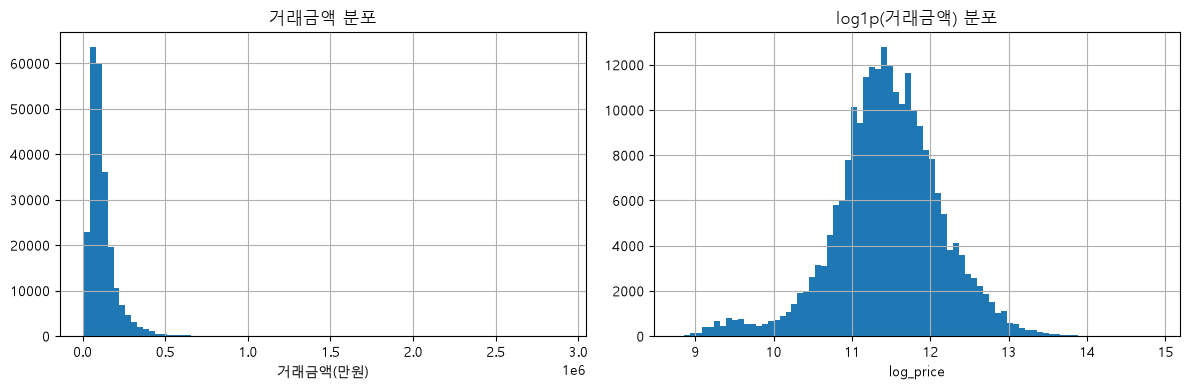

In [5]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

df_eda[price_col].hist(
    bins=80,
    ax=axes[0]
)
axes[0].set_title("거래금액 분포")
axes[0].set_xlabel("거래금액(만원)")

np.log1p(
    df_eda[price_col]
).hist(
    bins=80,
    ax=axes[1]
)
axes[1].set_title("log1p(거래금액) 분포")
axes[1].set_xlabel("log_price")

plt.tight_layout()
plt.show()


In [6]:
display(
    df_eda[price_col].describe(
        percentiles=[
            0.01,
            0.25,
            0.5,
            0.75,
            0.9,
            0.95,
            0.99
        ]
    )
)

count         234302.0
mean     117995.048642
std       90598.183195
min             6500.0
1%             12000.0
25%            64500.0
50%            94800.0
75%           144000.0
90%           216000.0
95%           281500.0
99%           450000.0
max          2900000.0
Name: 거래금액, dtype: Float64

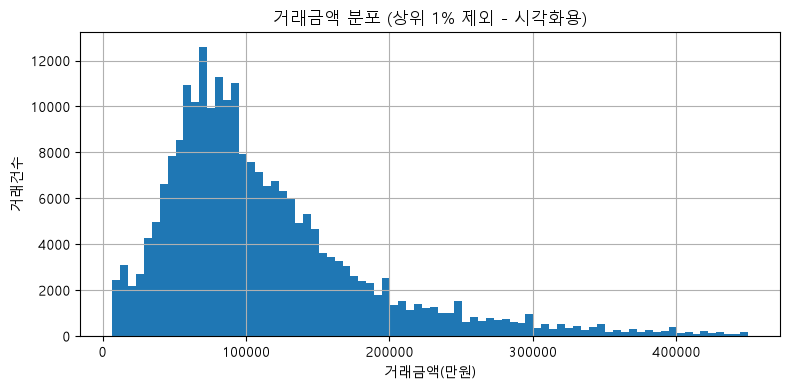

In [7]:
q99 = df_eda[price_col].quantile(0.99)

fig, ax = plt.subplots(
    figsize=(8, 4)
)

df_eda.loc[
    df_eda[price_col] <= q99,
    price_col
].hist(
    bins=80,
    ax=ax
)

ax.set_title(
    "거래금액 분포 "
    "(상위 1% 제외 - 시각화용)"
)

ax.set_xlabel("거래금액(만원)")
ax.set_ylabel("거래건수")

plt.tight_layout()
plt.show()

오른쪽 꼬리가 긴 부동산 가격 분포는 로그변환 후 상대적으로 완화됩니다.

다만 5년 데이터에서는 연도별 가격 수준 자체가 바뀌므로,
이 분포만 보고 모델을 결정하지 않고 **시간순 검증 성능**을 최종 판단 기준으로 사용합니다.


## 2. 기본 + 시간 피처 엔지니어링

### 정적/기본 피처
- `연식` = 계약년도 - 건축년도
- `층_구분` = 저층 / 중층 / 고층
- `log_price` = log1p(거래금액) — **회귀 타겟/분석용**
- `평당가` — **현재 거래금액에서 직접 계산되므로 회귀 입력 금지**

### 5년용 시간 피처
- `거래년도`
- `거래월`
- `분기`
- `거래연월`
- `거래월일자`
- `경과월`
- `월_sin`, `월_cos` — 12개월 계절성 표현

`평당가`는 기존 하위 노트북 호환을 위해 이름을 유지하되,
이번 버전에서는 실제 **평(3.3058㎡)당 가격**으로 계산합니다.


In [8]:
df_fe = df_eda.copy()

before_merge_rows = len(df_fe)


# ============================================================
# 1. 날짜 / 시간 피처
# ============================================================

df_fe["거래년도"] = (
    df_fe["계약년도"]
    .astype("Int64")
)

df_fe["거래월"] = (
    df_fe["계약월"]
    .astype("Int64")
)

df_fe["분기"] = (
    ((df_fe["거래월"] - 1) // 3 + 1)
    .astype("Int64")
)

# 표시/그룹핑용 YYYYMM
df_fe["거래연월"] = (
    df_fe["거래년도"] * 100
    + df_fe["거래월"]
)


# 월 단위 실제 날짜
df_fe["거래월일자"] = pd.to_datetime(
    dict(
        year=df_fe["거래년도"],
        month=df_fe["거래월"],
        day=1,
    ),
    errors="coerce"
)


# ============================================================
# 2. 시간 경과 피처
# ============================================================

base_month = df_fe["거래월일자"].min()

df_fe["경과월"] = (
    (df_fe["거래월일자"].dt.year - base_month.year) * 12
    + (
        df_fe["거래월일자"].dt.month
        - base_month.month
    )
)


# 계절성 표현
df_fe["월_sin"] = np.sin(
    2 * np.pi * df_fe["거래월"] / 12
)

df_fe["월_cos"] = np.cos(
    2 * np.pi * df_fe["거래월"] / 12
)


# ============================================================
# 3. 기본 물리 피처
# ============================================================

df_fe["연식"] = (
    df_fe["거래년도"]
    - df_fe["건축년도"]
)

# 비정상 연식 제거
df_fe.loc[
    (df_fe["연식"] < 0)
    | (df_fe["연식"] > 100),
    "연식"
] = pd.NA


def floor_group(f):
    if pd.isna(f):
        return np.nan

    if f <= 5:
        return "저층"

    if f <= 15:
        return "중층"

    return "고층"


df_fe["층_구분"] = (
    df_fe["층"]
    .apply(floor_group)
)


# ============================================================
# 4. 타겟 / 분석 전용 피처
# ============================================================

# 회귀 입력 X로 사용 금지
df_fe["log_price"] = np.log1p(
    df_fe[price_col]
)


# 현재 거래가격 기반 → 회귀 입력 X로 사용 금지
valid_area = (
    df_fe["전용면적"].notna()
    & (df_fe["전용면적"] > 0)
)

df_fe["평당가"] = np.nan

df_fe.loc[
    valid_area,
    "평당가"
] = (
    df_fe.loc[valid_area, price_col]
    / (
        df_fe.loc[valid_area, "전용면적"]
        / 3.3058
    )
)
df_fe["log_평당가"] = np.log1p(
    df_fe["평당가"]
)

# ============================================================
# 5. 시군구 코드 정리
# ============================================================

df_fe["법정동시군구코드"] = (
    df_fe["법정동시군구코드"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

region_map = (
    sigungu_df[
        [
            "시군구코드",
            "시군구명",
            "시도명"
        ]
    ]
    .drop_duplicates("시군구코드")
    .copy()
)

region_map["시군구코드"] = (
    region_map["시군구코드"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)


# ============================================================
# 6. 지역 정보 매핑
# ============================================================

df_fe = df_fe.merge(
    region_map,
    left_on="법정동시군구코드",
    right_on="시군구코드",
    how="left",
    validate="many_to_one"
)


# ============================================================
# 7. 검증
# ============================================================

print("shape:", df_fe.shape)

print(
    "merge 전/후 행 수:",
    before_merge_rows,
    "→",
    len(df_fe)
)

print(
    "시군구명 결측치:",
    df_fe["시군구명"].isna().sum()
)

print(
    "연식 결측치:",
    df_fe["연식"].isna().sum()
)

print(
    "평당가 결측치:",
    df_fe["평당가"].isna().sum()
)

print(
    "거래 기간:",
    df_fe["거래월일자"].min(),
    "~",
    df_fe["거래월일자"].max()
)

print(
    "거래 월 수:",
    df_fe["거래월일자"]
    .dt.to_period("M")
    .nunique()
)
print(
    "log_평당가 결측치:",
    df_fe["log_평당가"].isna().sum()
)
display(
    df_fe[
        [
            "법정동시군구코드",
            "시군구명",
            "거래년도",
            "거래월",
            "분기",
            "경과월",
            "월_sin",
            "월_cos",
            "연식",
            "층_구분",
            "평당가",
            "log_평당가",
            "log_price",
        ]
    ].head()
)

shape: (234302, 49)
merge 전/후 행 수: 234302 → 234302
시군구명 결측치: 0
연식 결측치: 19
평당가 결측치: 0
거래 기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00
거래 월 수: 60
log_평당가 결측치: 0


,법정동시군구코드,시군구명,거래년도,거래월,분기,경과월,월_sin,월_cos,연식,층_구분,평당가,log_평당가,log_price
0,11110,종로구,2021,7,3,0,-0.5,-0.866025,21,중층,4027.954743,8.301262,11.849405
1,11110,종로구,2021,7,3,0,-0.5,-0.866025,13,중층,4827.006666,8.482189,11.835016
2,11110,종로구,2021,7,3,0,-0.5,-0.866025,4,저층,7384.075921,8.907216,12.149508
3,11110,종로구,2021,7,3,0,-0.5,-0.866025,17,중층,4503.515417,8.412836,12.23077
4,11110,종로구,2021,7,3,0,-0.5,-0.866025,28,중층,4218.370018,8.347441,11.153404


In [9]:
display(
    df_fe.loc[
        df_fe["연식"].isna(),
        [
            "단지명",
            "시군구명",
            "계약년도",
            "건축년도",
            "연식",
            "거래금액",
        ]
    ]
)

,단지명,시군구명,계약년도,건축년도,연식,거래금액
86188,은평서해그랑블,은평구,2021,2022,<NA>,50000
86334,DMCSKVIEW,은평구,2022,2023,<NA>,137000
88902,DMC파인시티자이,은평구,2024,2025,<NA>,95368
89402,DMC파인시티자이,은평구,2024,2025,<NA>,104000
90261,DMC아트포레자이,은평구,2024,2026,<NA>,112000
91457,센트레빌아스테리움시그니처,은평구,2025,2026,<NA>,77500
91967,DMC아트포레자이,은평구,2025,2026,<NA>,119900
92528,센트레빌아스테리움시그니처,은평구,2025,2026,<NA>,72900
95185,힐스테이트신촌,서대문구,2021,2023,<NA>,168000
95903,힐스테이트신촌,서대문구,2022,2023,<NA>,137700


In [10]:
# 월별 서울 전체 시장 흐름
monthly_market = (
    df_fe
    .groupby("거래월일자")
    .agg(
        중위거래가격=("거래금액", "median"),
        평균거래가격=("거래금액", "mean"),
        중위평당가=("평당가", "median"),
        거래량=("거래금액", "size"),
    )
    .reset_index()
)

display(monthly_market.head())
print("월 수:", len(monthly_market))

,거래월일자,중위거래가격,평균거래가격,중위평당가,거래량
0,2021-07-01,87000.0,104320.469532,4087.030323,4677
1,2021-08-01,91000.0,107007.681034,4261.136937,4060
2,2021-09-01,92000.0,111700.588104,4444.230230,2690
3,2021-10-01,89500.0,108124.272313,4308.318427,2196
4,2021-11-01,83100.0,105230.310294,4056.025891,1360


월 수: 60


기존 1년 버전과 달리 시간 피처가 추가됩니다.

`log_price`와 `평당가`는 **현재 거래금액을 직접 사용해 만든 값**이므로:
- 군집/EDA에서 가격 자체를 분석할 때는 사용 가능
- 회귀에서 `거래금액`을 예측하는 입력 피처로는 사용 금지

향후 회귀에 넣을 가격 맥락 피처는 아래의 **과거 월 lag 통계**를 사용합니다.


In [11]:
# ============================================================
# 연식 및 시간 피처 검증
# ============================================================

valid_age = df_fe["연식"].dropna()

print("[연식 분포]")
print(valid_age.describe())

print(
    "\n5년 이내 신축 비율:",
    round(
        (valid_age <= 5).mean(),
        3
    )
)

print(
    "연식 결측:",
    df_fe["연식"].isna().sum()
)


print("\n[시간 피처]")

display(
    df_fe[
        [
            "거래년도",
            "거래월",
            "분기",
            "경과월",
            "월_sin",
            "월_cos",
        ]
    ].describe()
)

print(
    "경과월 범위:",
    df_fe["경과월"].min(),
    "~",
    df_fe["경과월"].max()
)

[연식 분포]
count     234283.0
mean     20.986329
std      11.398722
min            0.0
25%           12.0
50%           22.0
75%           29.0
max           65.0
Name: 연식, dtype: Float64

5년 이내 신축 비율: 0.117
연식 결측: 19

[시간 피처]


,거래년도,거래월,분기,경과월,월_sin,월_cos
count,234302.0,234302.0,234302.0,234302.000000,234302.0,234302.0
mean,2024.213553,6.092662,2.354487,37.655304,0.058462,-0.179152
std,1.389235,3.062186,1.022056,16.020675,0.710815,0.677667
min,2021.0,1.0,1.0,0.000000,-1.0,-1.0
25%,2023.0,4.0,2.0,28.000000,-0.5,-0.866025
50%,2024.0,6.0,2.0,41.000000,0.0,-0.5
75%,2025.0,8.0,3.0,50.000000,0.866025,0.5
max,2026.0,12.0,4.0,59.000000,1.0,1.0


경과월 범위: 0 ~ 59


In [12]:
(df_fe["연식"] <= 5).mean()

np.float64(0.1168245241865607)

In [13]:
def age_group(age):
    if pd.isna(age):
        return pd.NA
    if age <= 5:
        return "신축"
    elif age <= 15:
        return "준신축"
    elif age <= 30:
        return "중년식"
    else:
        return "구축"

df_fe["연식_구분"] = (
    df_fe["연식"]
    .apply(age_group)
)

In [14]:
df_fe.columns

Index(['법정동시군구코드', '법정동읍면동코드', '법정동지번코드', '법정동본번코드', '법정동부번코드', '도로명',
       '도로명시군구코드', '도로명코드', '도로명일련번호코드', '도로명지상지하코드', '도로명건물본번호코드',
       '도로명건물부번호코드', '법정동', '단지명', '지번', '전용면적', '계약년도', '계약월', '계약일', '거래금액',
       '층', '건축년도', '단지일련번호', '해제여부', '해제사유발생일', '거래유형', '중개사소재지', '등기일자',
       '아파트동명', '매도자', '매수자', '토지임대부아파트여부', '거래연월', '계약일자', '거래년도', '거래월',
       '분기', '거래월일자', '경과월', '월_sin', '월_cos', '연식', '층_구분', 'log_price',
       '평당가', 'log_평당가', '시군구코드', '시군구명', '시도명', '연식_구분'],
      dtype='object')

연식 분포는 구별 주택 재고 구성과 거래량에 따라 크게 다를 수 있습니다.

5년 데이터에서는 특정 연도에 신축 입주가 집중되거나,
거래절벽 시기에 표본 구성이 달라질 수 있으므로 전체 평균만으로 시장 특성을 단정하지 않습니다.


## 3. 서울 수집 범위 검증

V2 수집 노트북은 처음부터 서울 25개 구만 호출합니다.

여기서는 전국 데이터에서 서울을 다시 자르는 단계가 아니라:
- 서울 외 데이터가 섞였는지
- 25개 구가 모두 존재하는지
- 월별/구별 누락이 있는지

를 검증합니다.


In [15]:
# ============================================================
# 서울 데이터 범위 검증
# ============================================================

seoul_names = set(
    sigungu_df["시군구명"]
)

non_seoul_mask = ~df_fe["시군구명"].isin(
    seoul_names
)

non_seoul_count = int(
    non_seoul_mask.sum()
)

print(
    "서울 외 데이터 건수:",
    non_seoul_count
)

if non_seoul_count > 0:
    raise ValueError(
        f"서울 외 데이터가 {non_seoul_count:,}건 존재합니다. "
        "수집 또는 지역 매핑 과정을 확인하세요."
    )


# ============================================================
# 최종 범위 확인
# ============================================================

print(
    "서울 구 수:",
    df_fe["시군구명"].nunique()
)

print(
    "거래 기간:",
    df_fe["거래월일자"].min(),
    "~",
    df_fe["거래월일자"].max()
)

print(
    "거래 월 수:",
    df_fe["거래월일자"]
    .dt.to_period("M")
    .nunique()
)

print(
    "최종 서울 shape:",
    df_fe.shape
)

서울 외 데이터 건수: 0
서울 구 수: 25
거래 기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00
거래 월 수: 60
최종 서울 shape: (234302, 50)


서울만 남긴 뒤에도 **60개월 전체가 존재하는지** 확인해야 합니다.

특정 구×월 조합의 거래가 실제로 0건일 수도 있지만,
많은 조합이 동시에 누락된다면 데이터 수집 실패 가능성을 먼저 점검합니다.


## 4. 5년 시간축 EDA

1년 데이터에서는 단순 월별 추이만 봐도 충분했지만,
5년 데이터에서는 **시장 상승/하락/회복 구간과 거래량 변화**를 함께 확인합니다.

먼저 연도별 거래량과 중위가격, 월별 거래량과 중위가격을 확인합니다.


,거래년도,거래건수,중위거래금액,평균거래금액,중위평당가,거래개월수,월평균거래건수
0,2021,16113,89000.0,106940.318501,4216.300433,6,2685.5
1,2022,12047,73000.0,96021.342658,3890.091786,12,1003.916667
2,2023,34034,87000.0,106330.183904,4056.260789,12,2836.166667
3,2024,55174,96000.0,120072.489198,4370.117135,12,4597.833333
4,2025,77365,104500.0,126954.824507,4670.308453,12,6447.083333
5,2026,39569,93000.0,118805.034851,4251.426454,6,6594.833333


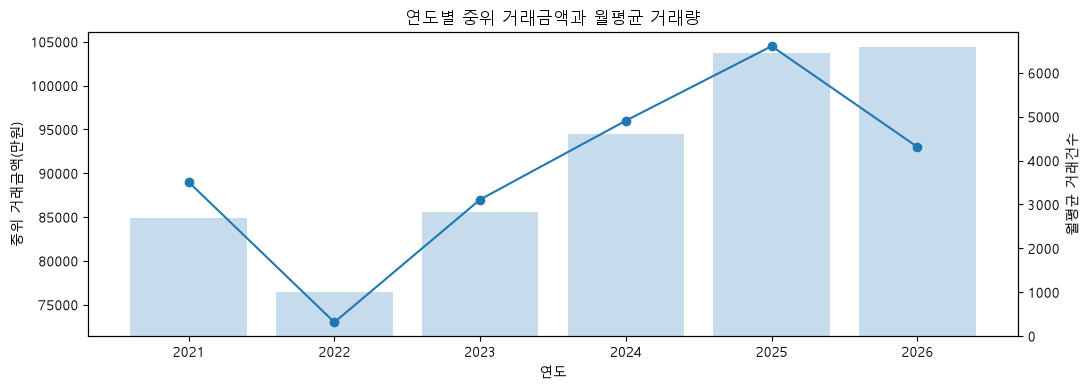

In [16]:
yearly_market = (
    df_fe
    .groupby("거래년도")
    .agg(
        거래건수=(price_col, "size"),
        중위거래금액=(price_col, "median"),
        평균거래금액=(price_col, "mean"),
        중위평당가=("평당가", "median"),
        거래개월수=("거래월", "nunique"),
    )
    .reset_index()
)

# 월평균 거래량
yearly_market["월평균거래건수"] = (
    yearly_market["거래건수"]
    / yearly_market["거래개월수"]
)

display(yearly_market)


# ============================================================
# 시각화
# ============================================================

fig, ax1 = plt.subplots(
    figsize=(11, 4)
)

# 중위 거래금액
ax1.plot(
    yearly_market["거래년도"],
    yearly_market["중위거래금액"],
    marker="o"
)

ax1.set_xlabel("연도")
ax1.set_ylabel("중위 거래금액(만원)")


# 월평균 거래량
ax2 = ax1.twinx()

ax2.bar(
    yearly_market["거래년도"],
    yearly_market["월평균거래건수"],
    alpha=0.25
)

ax2.set_ylabel("월평균 거래건수")


plt.title(
    "연도별 중위 거래금액과 월평균 거래량"
)

plt.tight_layout()
plt.show()

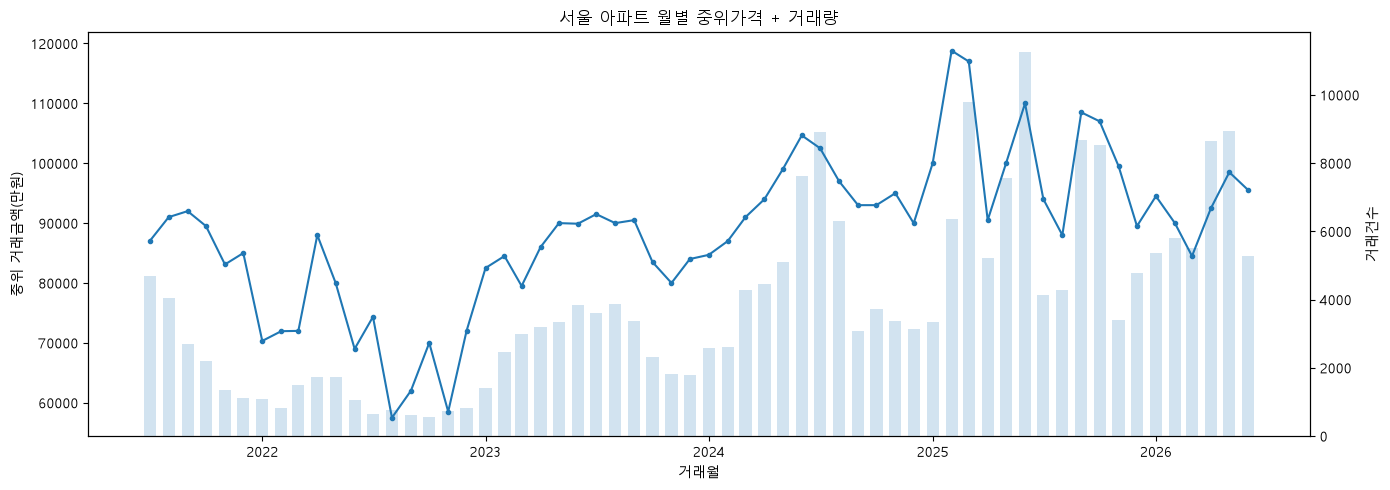

,거래월일자,거래건수,중위거래금액,평균거래금액
48,2025-07-01,4149,94000.0,127796.373584
49,2025-08-01,4277,88000.0,105568.02946
50,2025-09-01,8665,108500.0,121156.829429
51,2025-10-01,8533,107000.0,126497.501113
52,2025-11-01,3390,99500.0,130716.00413
53,2025-12-01,4774,89500.0,109305.029535
54,2026-01-01,5373,94500.0,117316.63968
55,2026-02-01,5796,90000.0,111461.557798
56,2026-03-01,5514,84500.0,105080.770584
57,2026-04-01,8656,92500.0,121894.32128


In [17]:
monthly_market = (
    df_fe.groupby("거래월일자")
    .agg(
        거래건수=(price_col, "size"),
        중위거래금액=(price_col, "median"),
        평균거래금액=(price_col, "mean"),
    )
    .reset_index()
    .sort_values("거래월일자")
)

fig, ax1 = plt.subplots(
    figsize=(14, 5)
)

ax1.plot(
    monthly_market["거래월일자"],
    monthly_market["중위거래금액"],
    marker="o",
    markersize=3
)
ax1.set_ylabel("중위 거래금액(만원)")
ax1.set_xlabel("거래월")

ax2 = ax1.twinx()
ax2.bar(
    monthly_market["거래월일자"],
    monthly_market["거래건수"],
    width=20,
    alpha=0.2
)
ax2.set_ylabel("거래건수")

plt.title("서울 아파트 월별 중위가격 + 거래량")
plt.tight_layout()
plt.show()

display(monthly_market.tail(12))


In [18]:
monthly_market["중위거래금액_3M"] = (
    monthly_market["중위거래금액"]
    .rolling(
        window=3,
        min_periods=1
    )
    .median()
)

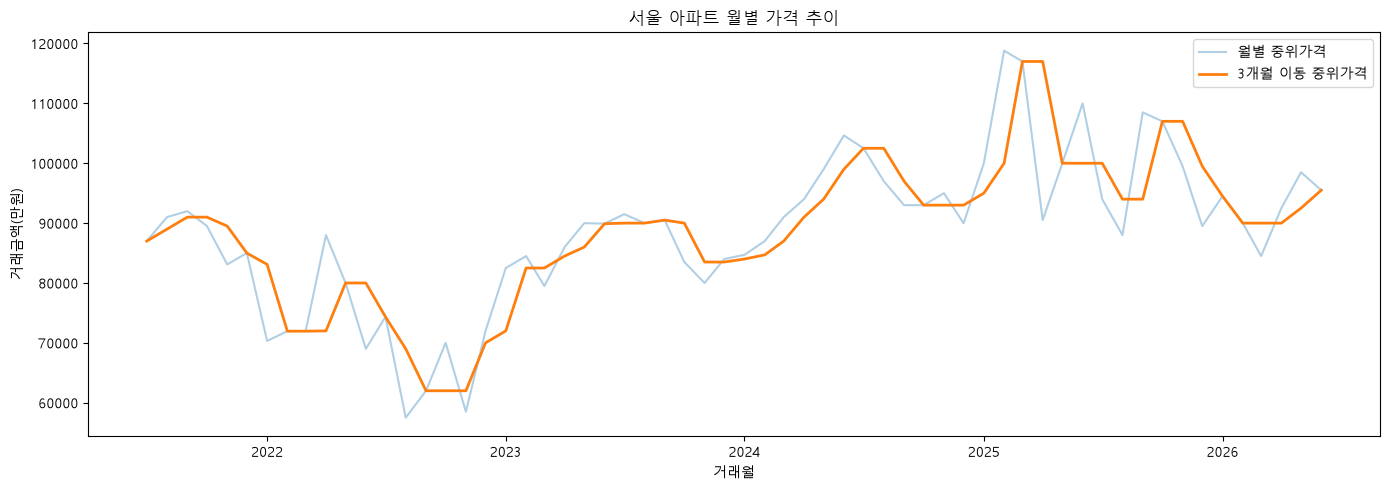

In [19]:
fig, ax = plt.subplots(
    figsize=(14, 5)
)

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["중위거래금액"],
    alpha=0.35,
    label="월별 중위가격"
)

ax.plot(
    monthly_market["거래월일자"],
    monthly_market["중위거래금액_3M"],
    linewidth=2,
    label="3개월 이동 중위가격"
)

ax.set_xlabel("거래월")
ax.set_ylabel("거래금액(만원)")
ax.set_title("서울 아파트 월별 가격 추이")

ax.legend()

plt.tight_layout()
plt.show()

### 최근 월 신고 지연 체크

가장 최근 월 거래량이 직전 몇 달보다 지나치게 작으면 시장 급변이 아니라 **신고 미완결**일 수 있습니다.

이 경우 `01_data_collection_5year.ipynb`의 `REPORTING_LAG_MONTHS`를 2보다 더 크게 잡고 다시 수집하는 것이 안전합니다.


In [20]:
recent_counts = (
    monthly_market
    .set_index("거래월일자")["거래건수"]
    .tail(12)
)

display(recent_counts)

if len(recent_counts) >= 4:

    recent_month = recent_counts.index[-1]
    recent_count = recent_counts.iloc[-1]

    prev_3months = recent_counts.iloc[-4:-1]
    prev_median = prev_3months.median()

    ratio = (
        recent_count / prev_median
        if prev_median > 0
        else np.nan
    )

    print(
        "\n최근월:",
        recent_month.strftime("%Y-%m")
    )

    print(
        "최근월 거래건수:",
        f"{recent_count:,}"
    )

    print(
        "직전 3개월 거래건수 중앙값:",
        f"{prev_median:,.0f}"
    )

    print(
        "최근월 / 직전3개월 중앙값 비율:",
        round(ratio, 3)
    )

    if ratio < 0.6:
        print(
            "⚠ 최근월 거래량이 직전 3개월 대비 많이 낮습니다."
        )
        print(
            "신고 지연 또는 실제 거래량 급감 여부를 확인하세요."
        )
    else:
        print(
            "✅ 최근월 거래량은 크게 비정상적이지 않습니다."
        )

거래월일자
2025-07-01    4149
2025-08-01    4277
2025-09-01    8665
2025-10-01    8533
2025-11-01    3390
2025-12-01    4774
2026-01-01    5373
2026-02-01    5796
2026-03-01    5514
2026-04-01    8656
2026-05-01    8952
2026-06-01    5278
Name: 거래건수, dtype: Int64


최근월: 2026-06
최근월 거래건수: 5,278
직전 3개월 거래건수 중앙값: 8,656
최근월 / 직전3개월 중앙값 비율: 0.61
✅ 최근월 거래량은 크게 비정상적이지 않습니다.


## 5. 누수 없는 과거 월 기반 시장 피처

현재 거래의 가격을 이용한 `지역평균가`, `평당가`, 현재월 지역 통계는 회귀 입력으로 쓰면 누수가 발생할 수 있습니다.

따라서 각 거래월 **이전 월까지의 정보만** 사용한 지역별 시계열 피처를 만듭니다.

생성 예:
- `구_전월_중위가격`
- `구_과거3개월_중위가격`
- `구_과거6개월_중위가격`
- `구_전월_거래량`
- `구_과거3개월_거래량`
- `구_전월_가격변화율`
- `서울_전월_중위가격`

첫 몇 달은 과거 이력이 부족하므로 NaN이 자연스럽게 발생하며,
최종 회귀에서 Train 기준 fallback/imputation을 적용합니다.

> 이 피처들은 월별로 순차 갱신되는 서비스 시나리오를 가정한 causal lag입니다.
> 최종 고정 holdout 평가 정책은 `04_regression`에서 명시적으로 다시 고정합니다.


In [21]:
# ============================================================
# 과거 시장 Lag Feature 생성
# ============================================================

# 셀 재실행 시 기존 lag 컬럼 중복 방지
old_lag_cols = [
    "구_전월_중위가격",
    "구_전월_중위평당가",
    "구_전월_거래량",
    "구_과거3개월_중위가격",
    "구_과거6개월_중위가격",
    "구_과거3개월_거래량",
    "구_과거6개월_거래량",
    "구_전월_가격변화율",
    "서울_전월_중위가격",
    "서울_과거3개월_중위가격",
    "서울_과거6개월_중위가격",
    "서울_전월_거래량",
    "서울_과거3개월_거래량",
    "서울_전월_가격변화율",
]

df_fe = df_fe.drop(
    columns=[
        col for col in old_lag_cols
        if col in df_fe.columns
    ],
    errors="ignore"
)


# ------------------------------------------------------------
# 1. 구 × 월 원 통계
# 현재월 통계 자체는 분석용
# 회귀에는 아래에서 shift한 값만 사용
# ------------------------------------------------------------

monthly_region_stats = (
    df_fe
    .groupby(
        [
            "법정동시군구코드",
            "시군구명",
            "거래월일자",
        ]
    )
    .agg(
        월중위거래금액=(price_col, "median"),
        월평균거래금액=(price_col, "mean"),
        월중위평당가=("평당가", "median"),
        월거래량=(price_col, "size"),
    )
    .reset_index()
    .sort_values(
        [
            "법정동시군구코드",
            "거래월일자",
        ]
    )
)


region_group = monthly_region_stats.groupby(
    "법정동시군구코드",
    group_keys=False
)


# ------------------------------------------------------------
# 2. 구 단위 과거 시장 피처
# t월 예측 → t-1 이전 데이터만 사용
# ------------------------------------------------------------

monthly_region_stats["구_전월_중위가격"] = (
    region_group["월중위거래금액"]
    .shift(1)
)

monthly_region_stats["구_전월_중위평당가"] = (
    region_group["월중위평당가"]
    .shift(1)
)

monthly_region_stats["구_전월_거래량"] = (
    region_group["월거래량"]
    .shift(1)
)


# 과거 3개월
monthly_region_stats["구_과거3개월_중위가격"] = (
    region_group["월중위거래금액"]
    .transform(
        lambda s:
            s.shift(1)
            .rolling(
                window=3,
                min_periods=3
            )
            .median()
    )
)

monthly_region_stats["구_과거3개월_거래량"] = (
    region_group["월거래량"]
    .transform(
        lambda s:
            s.shift(1)
            .rolling(
                window=3,
                min_periods=3
            )
            .sum()
    )
)


# 과거 6개월
monthly_region_stats["구_과거6개월_중위가격"] = (
    region_group["월중위거래금액"]
    .transform(
        lambda s:
            s.shift(1)
            .rolling(
                window=6,
                min_periods=6
            )
            .median()
    )
)

monthly_region_stats["구_과거6개월_거래량"] = (
    region_group["월거래량"]
    .transform(
        lambda s:
            s.shift(1)
            .rolling(
                window=6,
                min_periods=6
            )
            .sum()
    )
)


# t월에서 사용 가능한 가장 최근 가격 변화
# (t-1 가격 / t-2 가격) - 1
monthly_region_stats["구_전월_가격변화율"] = (
    region_group["월중위거래금액"]
    .transform(
        lambda s:
            s.shift(1) / s.shift(2) - 1
    )
)


# ------------------------------------------------------------
# 3. 서울 전체 월별 시장
# ------------------------------------------------------------

seoul_monthly_stats = (
    df_fe
    .groupby("거래월일자")
    .agg(
        서울_월중위가격=(price_col, "median"),
        서울_월거래량=(price_col, "size"),
    )
    .reset_index()
    .sort_values("거래월일자")
)


# 전월
seoul_monthly_stats["서울_전월_중위가격"] = (
    seoul_monthly_stats["서울_월중위가격"]
    .shift(1)
)

seoul_monthly_stats["서울_전월_거래량"] = (
    seoul_monthly_stats["서울_월거래량"]
    .shift(1)
)


# 과거 3개월
seoul_monthly_stats["서울_과거3개월_중위가격"] = (
    seoul_monthly_stats["서울_월중위가격"]
    .shift(1)
    .rolling(
        window=3,
        min_periods=3
    )
    .median()
)

seoul_monthly_stats["서울_과거3개월_거래량"] = (
    seoul_monthly_stats["서울_월거래량"]
    .shift(1)
    .rolling(
        window=3,
        min_periods=3
    )
    .sum()
)


# 과거 6개월
seoul_monthly_stats["서울_과거6개월_중위가격"] = (
    seoul_monthly_stats["서울_월중위가격"]
    .shift(1)
    .rolling(
        window=6,
        min_periods=6
    )
    .median()
)


# 가격 변화율
seoul_monthly_stats["서울_전월_가격변화율"] = (
    seoul_monthly_stats["서울_월중위가격"]
    .shift(1)
    / seoul_monthly_stats["서울_월중위가격"]
    .shift(2)
    - 1
)


# ------------------------------------------------------------
# 4. Merge
# ------------------------------------------------------------

lag_region_cols = [
    "구_전월_중위가격",
    "구_전월_중위평당가",
    "구_전월_거래량",
    "구_과거3개월_중위가격",
    "구_과거6개월_중위가격",
    "구_과거3개월_거래량",
    "구_과거6개월_거래량",
    "구_전월_가격변화율",
]

seoul_lag_cols = [
    "서울_전월_중위가격",
    "서울_과거3개월_중위가격",
    "서울_과거6개월_중위가격",
    "서울_전월_거래량",
    "서울_과거3개월_거래량",
    "서울_전월_가격변화율",
]


before_rows = len(df_fe)

df_fe = df_fe.merge(
    monthly_region_stats[
        [
            "법정동시군구코드",
            "거래월일자",
        ]
        + lag_region_cols
    ],
    on=[
        "법정동시군구코드",
        "거래월일자",
    ],
    how="left",
    validate="many_to_one",
)

df_fe = df_fe.merge(
    seoul_monthly_stats[
        ["거래월일자"]
        + seoul_lag_cols
    ],
    on="거래월일자",
    how="left",
    validate="many_to_one",
)


# ------------------------------------------------------------
# 5. 검증
# ------------------------------------------------------------

print("[과거 시장 피처 생성 완료]")

print(
    "merge 전/후:",
    before_rows,
    "→",
    len(df_fe)
)

print(
    "지역×월 행 수:",
    len(monthly_region_stats)
)

print(
    "지역 수:",
    monthly_region_stats[
        "법정동시군구코드"
    ].nunique()
)

print(
    "월 수:",
    monthly_region_stats[
        "거래월일자"
    ].nunique()
)


lag_cols = (
    lag_region_cols
    + seoul_lag_cols
)

display(
    df_fe[
        [
            "시군구명",
            "거래월일자",
        ]
        + lag_cols
    ].head(20)
)

print("\n[lag 피처 결측 비율]")

display(
    df_fe[lag_cols]
    .isna()
    .mean()
    .sort_values(ascending=False)
    .to_frame("결측비율")
)

[과거 시장 피처 생성 완료]
merge 전/후: 234302 → 234302
지역×월 행 수: 1500
지역 수: 25
월 수: 60


,시군구명,거래월일자,구_전월_중위가격,구_전월_중위평당가,구_전월_거래량,구_과거3개월_중위가격,구_과거6개월_중위가격,구_과거3개월_거래량,구_과거6개월_거래량,구_전월_가격변화율,서울_전월_중위가격,서울_과거3개월_중위가격,서울_과거6개월_중위가격,서울_전월_거래량,서울_과거3개월_거래량,서울_전월_가격변화율
0,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
1,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
2,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
3,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
4,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
5,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
6,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
7,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
8,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>
9,종로구,2021-07-01,<NA>,NaN,<NA>,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,<NA>,NaN,<NA>



[lag 피처 결측 비율]


,결측비율
구_과거6개월_중위가격,0.068770
구_과거6개월_거래량,0.068770
서울_과거6개월_중위가격,0.068770
서울_과거3개월_거래량,0.048770
구_과거3개월_거래량,0.048770
구_과거3개월_중위가격,0.048770
서울_과거3개월_중위가격,0.048770
서울_전월_가격변화율,0.037289
구_전월_가격변화율,0.037289
구_전월_중위가격,0.019961


In [22]:
reg_df = (
    df_fe[
        df_fe["거래월일자"]
        >= pd.Timestamp("2022-01-01")
    ]
    .copy()
)

print(
    "회귀 데이터 기간:",
    reg_df["거래월일자"].min(),
    "~",
    reg_df["거래월일자"].max()
)

print(
    "회귀 데이터 shape:",
    reg_df.shape
)

회귀 데이터 기간: 2022-01-01 00:00:00 ~ 2026-06-01 00:00:00
회귀 데이터 shape: (218189, 64)


In [23]:
lag_cols = (
    lag_region_cols
    + seoul_lag_cols
)

display(
    reg_df[lag_cols]
    .isna()
    .sum()
    .to_frame("결측건수")
)

,결측건수
구_전월_중위가격,0
구_전월_중위평당가,0
구_전월_거래량,0
구_과거3개월_중위가격,0
구_과거6개월_중위가격,0
구_과거3개월_거래량,0
구_과거6개월_거래량,0
구_전월_가격변화율,0
서울_전월_중위가격,0
서울_과거3개월_중위가격,0


### 시장 국면 군집용 월별 테이블

`market_monthly_5y.parquet`에는 **지역×월 실제 집계값과 lag 피처**를 함께 저장합니다.

향후 `03_clustering`에서 거래행 자체가 아니라 `지역×월`을 한 관측치로 두고:
- 가격 변화율
- 거래량 변화
- 가격 변동성

등을 이용해 `상승 활황 / 침체 / 회복 초기` 같은 **시장 국면 군집**을 실험할 수 있습니다.

현재월 실제 통계는 시장 국면을 사후 분석하는 데 사용할 수 있지만,
미래 가격 회귀 입력으로 넣을 때는 lag 컬럼만 사용합니다.


## 6. 아파트 좌표 지오코딩 (카카오 API)

같은 단지는 5년 동안 여러 번 거래되므로,
`시군구명 + 법정동 + 지번 + 단지명`의 고유 주소 기준으로 캐싱해서 API 호출을 최소화합니다.

5년으로 거래행이 늘어나도 **고유 단지/주소 수는 거래건수만큼 증가하지 않으므로**
기존 `geocode_cache.csv`를 적극 재사용할 수 있습니다.


In [24]:
KAKAO_API_KEY = os.environ.get(
    "KAKAO_REST_API_KEY",
    ""
)

if not KAKAO_API_KEY:
    raise ValueError(
        "KAKAO_REST_API_KEY 환경변수가 설정되지 않았습니다."
    )


def geocode_address(query: str):
    url = (
        "https://dapi.kakao.com/"
        "v2/local/search/address.json"
    )

    headers = {
        "Authorization": f"KakaoAK {KAKAO_API_KEY}"
    }

    params = {
        "query": query
    }

    try:
        resp = requests.get(
            url,
            headers=headers,
            params=params,
            timeout=5
        )

        resp.raise_for_status()

        docs = resp.json().get(
            "documents",
            []
        )

        if not docs:
            print(
                f"⚠ 검색 결과 없음: {query}"
            )
            return None, None

        lat = float(docs[0]["y"])
        lon = float(docs[0]["x"])

        return lat, lon

    except requests.RequestException as e:
        print(
            f"❌ API 요청 실패: {query}"
        )
        print(e)

        return None, None


# 테스트
lat, lon = geocode_address(
    "서울특별시 종로구 숭인동"
)

print(
    "위도:",
    lat,
    "경도:",
    lon
)

위도: 37.5745280159936 경도: 127.019597569646


테스트 쿼리 "서울특별시 종로구 숭인동"이 위도 37.57 / 경도 127.02로 정상 반환되어, 카카오 지오코딩 API 연동이 정상 작동함을 확인했습니다.

In [25]:
# ============================================================
# 지오코딩용 주소 생성
# ============================================================

# 문자열 정리
for col in ["시군구명", "법정동", "지번", "단지명"]:
    df_fe[col] = (
        df_fe[col]
        .astype("string")
        .str.strip()
    )


# ------------------------------------------------------------
# 캐싱 / 단지 식별용 주소
# ------------------------------------------------------------

df_fe["주소"] = (
    "서울특별시 "
    + df_fe["시군구명"].fillna("")
    + " "
    + df_fe["법정동"].fillna("")
    + " "
    + df_fe["지번"].fillna("")
    + " "
    + df_fe["단지명"].fillna("")
).str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()


# ------------------------------------------------------------
# Kakao 지오코딩 검색용
# 단지명은 제외하고 지번 주소 중심으로 검색
# ------------------------------------------------------------

df_fe["검색주소"] = (
    "서울특별시 "
    + df_fe["시군구명"].fillna("")
    + " "
    + df_fe["법정동"].fillna("")
    + " "
    + df_fe["지번"].fillna("")
).str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()


# ------------------------------------------------------------
# 실제 API 호출 대상
# 검색주소 기준 중복 제거
# ------------------------------------------------------------

unique_address_df = (
    df_fe[
        [
            "검색주소",
        ]
    ]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

print(
    f"고유 검색주소 수: {len(unique_address_df):,}"
)

print(
    f"전체 거래 건수: {len(df_fe):,}"
)

display(
    unique_address_df.head()
)

고유 검색주소 수: 7,821
전체 거래 건수: 234,302


,검색주소
0,서울특별시 종로구 무악동 82
1,서울특별시 종로구 사직동 9
2,서울특별시 종로구 홍파동 199
3,서울특별시 종로구 내수동 73
4,서울특별시 종로구 창신동 703


실행 결과에서 **고유 주소 수 / 전체 거래건수 / 기존 캐시 재사용 수**를 확인합니다.

5년 데이터는 거래행이 크게 늘지만 동일 단지의 반복 거래가 많기 때문에,
실제 신규 지오코딩 API 호출 수는 거래행 증가폭보다 훨씬 작을 가능성이 큽니다.


In [26]:
# ============================================================
# 지오코딩 캐시 준비
# ============================================================

GEOCODE_CACHE_PATH = EXTERNAL_DIR / "geocode_cache.csv"
GEOCODE_COLUMNS = ["검색주소", "위도", "경도"]


def load_geocode_cache(path):
    """저장된 지오코딩 결과를 불러온다."""
    if not path.exists():
        return pd.DataFrame(columns=GEOCODE_COLUMNS)

    cache = pd.read_csv(
        path,
        encoding="utf-8-sig"
    )

    return (
        cache[GEOCODE_COLUMNS]
        .drop_duplicates("검색주소", keep="last")
        .reset_index(drop=True)
    )


geo_cache = load_geocode_cache(
    GEOCODE_CACHE_PATH
)

In [27]:
# ============================================================
# 지오코딩 대상 확인
# ============================================================

completed_addresses = set(
    geo_cache
    .dropna(subset=["위도", "경도"])
    ["검색주소"]
)

todo = (
    unique_address_df.loc[
        ~unique_address_df["검색주소"].isin(completed_addresses),
        "검색주소"
    ]
    .tolist()
)

print(f"전체 주소 : {len(unique_address_df):,}")
print(f"처리 완료 : {len(completed_addresses):,}")
print(f"처리 예정 : {len(todo):,}")

전체 주소 : 7,821
처리 완료 : 7,834
처리 예정 : 0


In [28]:
# ============================================================
# 지오코딩 샘플 테스트
# ============================================================

test_addresses = todo[:3]

for address in test_addresses:
    lat, lon = geocode_address(address)

    print(
        f"{address}"
        f"\n→ 위도: {lat}, 경도: {lon}\n"
    )

In [29]:
# ============================================================
# 지오코딩 수집 함수
# ============================================================

def collect_geocoding(
    addresses,
    cache_df,
    save_path,
    save_every=50,
    sleep_time=0.05
):
    results = []

    for i, address in enumerate(addresses, 1):
        lat, lon = geocode_address(address)

        results.append({
            "검색주소": address,
            "위도": lat,
            "경도": lon,
        })

        time.sleep(sleep_time)

        if i % save_every == 0 or i == len(addresses):
            new_data = pd.DataFrame(results)

            cache_df = (
                pd.concat(
                    [cache_df, new_data],
                    ignore_index=True
                )
                .drop_duplicates(
                    "검색주소",
                    keep="last"
                )
                .reset_index(drop=True)
            )

            cache_df.to_csv(
                save_path,
                index=False,
                encoding="utf-8-sig"
            )

            results = []

            print(
                f"진행: {i:,}/{len(addresses):,}"
            )

    return cache_df

In [30]:
# ============================================================
# 전체 지오코딩 실행
# ============================================================

geo_cache = collect_geocoding(
    addresses=todo,
    cache_df=geo_cache,
    save_path=GEOCODE_CACHE_PATH,
    save_every=50
)

실행 결과에서 **고유 주소 수 / 전체 거래건수 / 기존 캐시 재사용 수**를 확인합니다.

5년 데이터는 거래행이 크게 늘지만 동일 단지의 반복 거래가 많기 때문에,
실제 신규 지오코딩 API 호출 수는 거래행 증가폭보다 훨씬 작을 가능성이 큽니다.


In [31]:
# ============================================================
# 지오코딩 결과 확인
# ============================================================

total_count = len(geo_cache)

success_mask = (
    geo_cache["위도"].notna()
    & geo_cache["경도"].notna()
)

success_count = success_mask.sum()
fail_count = total_count - success_count

success_rate = (
    success_count / total_count
    if total_count > 0
    else 0
)

print(f"전체 주소 : {total_count:,}")
print(f"성공      : {success_count:,}")
print(f"실패      : {fail_count:,}")
print(f"성공률    : {success_rate:.1%}")

전체 주소 : 7,834
성공      : 7,834
실패      : 0
성공률    : 100.0%


In [32]:
# ============================================================
# 실패 주소 확인
# ============================================================

failed_geo = (
    geo_cache.loc[
        ~success_mask,
        ["검색주소"]
    ]
    .reset_index(drop=True)
)

print(f"실패 주소 수 : {len(failed_geo):,}")

display(
    failed_geo.head(20)
)

실패 주소 수 : 0


,검색주소


In [33]:
# ============================================================
# 실패 주소 원본 정보 확인
# ============================================================

failed_detail = (
    df_fe.loc[
        df_fe["검색주소"].isin(
            failed_geo["검색주소"]
        ),
        [
            "시군구명",
            "법정동",
            "지번",
            "단지명",
            "검색주소",
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

display(failed_detail)

,시군구명,법정동,지번,단지명,검색주소


In [34]:
# ============================================================
# 지오코딩 실패 영향 확인
# ============================================================

failed_mask = df_fe["검색주소"].isin(
    failed_geo["검색주소"]
)

failed_trade_count = failed_mask.sum()
failed_trade_rate = failed_trade_count / len(df_fe)

print(f"실패 주소 수   : {len(failed_geo):,}")
print(f"영향 거래 건수 : {failed_trade_count:,}")
print(f"영향 거래 비율 : {failed_trade_rate:.3%}")

실패 주소 수   : 0
영향 거래 건수 : 0
영향 거래 비율 : 0.000%


In [35]:
# ============================================================
# 실패 주소 원본 정보 확인
# ============================================================

road_cols = [
    "시군구명",
    "법정동",
    "지번",
    "단지명",
    "도로명",
    "도로명시군구코드",
    "도로명건물본번호코드",
    "도로명건물부번호코드",
    "검색주소",
]

available_cols = [
    col for col in road_cols
    if col in df_fe.columns
]

failed_detail = (
    df_fe.loc[
        failed_mask,
        available_cols
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

display(failed_detail)

,시군구명,법정동,지번,단지명,도로명,도로명시군구코드,도로명건물본번호코드,도로명건물부번호코드,검색주소


In [36]:
def format_building_number(main_no, sub_no):
    if pd.isna(main_no):
        return ""

    main_no = str(int(float(main_no)))

    if pd.isna(sub_no) or float(sub_no) == 0:
        return main_no

    return f"{main_no}-{int(float(sub_no))}"

In [37]:
# ============================================================
# 도로명 fallback 주소 생성
# ============================================================

failed_detail["건물번호"] = failed_detail.apply(
    lambda row: format_building_number(
        row.get("도로명건물본번호코드"),
        row.get("도로명건물부번호코드")
    ),
    axis=1
)

failed_detail["도로명검색주소"] = (
    "서울특별시 "
    + failed_detail["도로명"].fillna("")
    + " "
    + failed_detail["건물번호"].fillna("")
).str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

display(
    failed_detail[
        [
            "검색주소",
            "단지명",
            "도로명검색주소",
        ]
    ]
)

,검색주소,단지명,도로명검색주소


In [38]:
# ============================================================
# 도로명 주소로 2차 지오코딩
# ============================================================

fallback_results = []

for _, row in failed_detail.iterrows():
    lat, lon = geocode_address(
        row["도로명검색주소"]
    )

    fallback_results.append({
        "검색주소": row["검색주소"],
        "도로명검색주소": row["도로명검색주소"],
        "위도": lat,
        "경도": lon,
    })

fallback_geo = pd.DataFrame(
    fallback_results,
    columns=[
        "검색주소",
        "도로명검색주소",
        "위도",
        "경도",
    ],
)
display(fallback_geo)

,검색주소,도로명검색주소,위도,경도


In [39]:
# ============================================================
# 2차 검색 결과 반영
# ============================================================

fallback_success = (
    fallback_geo
    .dropna(subset=["위도", "경도"])
    .set_index("검색주소")
)

geo_cache = geo_cache.set_index("검색주소")

geo_cache.update(
    fallback_success[
        ["위도", "경도"]
    ]
)

geo_cache = geo_cache.reset_index()

geo_cache.to_csv(
    GEOCODE_CACHE_PATH,
    index=False,
    encoding="utf-8-sig"
)

In [40]:
success_mask = (
    geo_cache["위도"].notna()
    & geo_cache["경도"].notna()
)

print(
    "최종 실패 주소 수:",
    (~success_mask).sum()
)

최종 실패 주소 수: 0


In [41]:
# ============================================================
# 지오코딩 결과 병합
# ============================================================

before_rows = len(df_fe)

df_fe = df_fe.merge(
    geo_cache[
        [
            "검색주소",
            "위도",
            "경도",
        ]
    ],
    on="검색주소",
    how="left",
    validate="many_to_one"
)

print(
    "merge 전/후:",
    before_rows,
    "→",
    len(df_fe)
)

merge 전/후: 234302 → 234302


In [42]:
# ============================================================
# 좌표 병합 결과 확인
# ============================================================

coord_missing = (
    df_fe[
        [
            "위도",
            "경도",
        ]
    ]
    .isna()
    .any(axis=1)
    .sum()
)

print(f"전체 거래 건수 : {len(df_fe):,}")
print(f"좌표 결측 건수 : {coord_missing:,}")

display(
    df_fe[
        [
            "단지명",
            "검색주소",
            "위도",
            "경도",
        ]
    ].head()
)

전체 거래 건수 : 234,302
좌표 결측 건수 : 0


,단지명,검색주소,위도,경도
0,현대,서울특별시 종로구 무악동 82,37.575631,126.961060
1,광화문스페이스본(101동~105동),서울특별시 종로구 사직동 9,37.574417,126.968881
2,경희궁자이(2단지),서울특별시 종로구 홍파동 199,37.570696,126.963609
3,경희궁의아침4단지,서울특별시 종로구 내수동 73,37.572614,126.972273
4,창신쌍용2,서울특별시 종로구 창신동 703,37.580323,127.011785


In [43]:
# ============================================================
# 좌표 범위 검증
# ============================================================

coord_check = df_fe[
    ["위도", "경도"]
].describe()

display(coord_check)

invalid_coord = ~(
    df_fe["위도"].between(37.4, 37.8)
    & df_fe["경도"].between(126.7, 127.3)
)

print(
    f"서울 범위 밖 좌표 : {invalid_coord.sum():,}"
)

,위도,경도
count,234302.000000,234302.000000
mean,37.552068,126.996718
std,0.053197,0.090627
min,37.434446,126.806100
25%,37.506398,126.919327
50%,37.548594,127.016217
75%,37.589821,127.066174
max,37.687633,127.180765


서울 범위 밖 좌표 : 0


실행 후 좌표 매핑 성공률과 실패 주소 수를 확인합니다.

5년 확장으로 과거 단지까지 포함되면서 실패 주소가 늘 수 있으므로,
실패가 특정 단지/옛 지번에 집중되는지 별도로 확인합니다.


In [46]:
# ============================================================
# 거래별 고유 식별자 생성
# ============================================================

df_fe = df_fe.reset_index(drop=True)

if "transaction_id" not in df_fe.columns:
    df_fe.insert(
        0,
        "transaction_id",
        np.arange(len(df_fe))
    )

print("전체 거래 수:", len(df_fe))
print("고유 ID 수:", df_fe["transaction_id"].nunique())
print("중복 ID 수:", df_fe["transaction_id"].duplicated().sum())

display(
    df_fe[
        [
            "transaction_id",
            "시군구명",
            "법정동",
            "단지명",
            "거래월일자",
            "거래금액",
        ]
    ].head()
)

전체 거래 수: 234302
고유 ID 수: 234302
중복 ID 수: 0


,transaction_id,시군구명,법정동,단지명,거래월일자,거래금액
0,0,종로구,무악동,현대,2021-07-01,140000
1,1,종로구,사직동,광화문스페이스본(101동~105동),2021-07-01,138000
2,2,종로구,홍파동,경희궁자이(2단지),2021-07-01,189000
3,3,종로구,내수동,경희궁의아침4단지,2021-07-01,205000
4,4,종로구,창신동,창신쌍용2,2021-07-01,69800


In [45]:
print(df_fe.columns.tolist())

['transaction_id', '법정동시군구코드', '법정동읍면동코드', '법정동지번코드', '법정동본번코드', '법정동부번코드', '도로명', '도로명시군구코드', '도로명코드', '도로명일련번호코드', '도로명지상지하코드', '도로명건물본번호코드', '도로명건물부번호코드', '법정동', '단지명', '지번', '전용면적', '계약년도', '계약월', '계약일', '거래금액', '층', '건축년도', '단지일련번호', '해제여부', '해제사유발생일', '거래유형', '중개사소재지', '등기일자', '아파트동명', '매도자', '매수자', '토지임대부아파트여부', '거래연월', '계약일자', '거래년도', '거래월', '분기', '거래월일자', '경과월', '월_sin', '월_cos', '연식', '층_구분', 'log_price', '평당가', 'log_평당가', '시군구코드', '시군구명', '시도명', '연식_구분', '구_전월_중위가격', '구_전월_중위평당가', '구_전월_거래량', '구_과거3개월_중위가격', '구_과거6개월_중위가격', '구_과거3개월_거래량', '구_과거6개월_거래량', '구_전월_가격변화율', '서울_전월_중위가격', '서울_과거3개월_중위가격', '서울_과거6개월_중위가격', '서울_전월_거래량', '서울_과거3개월_거래량', '서울_전월_가격변화율', '주소', '검색주소', '위도', '경도']


In [47]:
# ============================================================
# 기본 피처 데이터 저장 (전처리 + 시간 피처 + 시장 lag 피처 + 좌표)
# ============================================================
# 지하철/학교 피처는 02_subway_feature_engineering.ipynb,
# 03_school_feature_engineering.ipynb에서 이 파일을 불러와 각각
# 별도 결과물로 저장한다. 세 결과의 병합은 이후 단계에서 진행한다.

DF_FE_BASE_PATH = PROCESSED_DIR / "df_fe_base.parquet"
MARKET_MONTHLY_PATH = PROCESSED_DIR / "market_monthly.parquet"

df_fe.to_parquet(
    DF_FE_BASE_PATH,
    index=False,
)

market_monthly = monthly_region_stats.merge(
    seoul_monthly_stats,
    on="거래월일자",
    how="left",
)

market_monthly.to_parquet(
    MARKET_MONTHLY_PATH,
    index=False,
)

print("[기본 피처 저장 완료]")
print("DF_FE_BASE_PATH     :", DF_FE_BASE_PATH.resolve())
print("MARKET_MONTHLY_PATH :", MARKET_MONTHLY_PATH.resolve())
print("df_fe shape          :", df_fe.shape)
print("market_monthly shape :", market_monthly.shape)


[기본 피처 저장 완료]
DF_FE_BASE_PATH     : C:\Users\UK\Apartment price\data\v2_5year_seoul\processed\df_fe_base.parquet
MARKET_MONTHLY_PATH : C:\Users\UK\Apartment price\data\v2_5year_seoul\processed\market_monthly.parquet
df_fe shape          : (234302, 69)
market_monthly shape : (1500, 23)


In [48]:
# 저장된 파일 재확인
saved_base_df = pd.read_parquet(DF_FE_BASE_PATH)

print("저장 행 수:", len(saved_base_df))
print(
    "transaction_id 존재:",
    "transaction_id" in saved_base_df.columns
)
print(
    "transaction_id 중복:",
    saved_base_df["transaction_id"].duplicated().sum()
)

저장 행 수: 234302
transaction_id 존재: True
transaction_id 중복: 0
